# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** M Fahril Luthfi
- **Email:** mfahrilluthfi@gmail.com
- **ID Dicoding:** m_fahril_luthfit7lm

## Pendahuluan

Proyek ini menganalisis **E-Commerce Public Dataset** (data transaksi marketplace di Brasil, 2016–2018) yang terdiri dari beberapa tabel: pelanggan, pesanan, item pesanan, pembayaran, ulasan, produk, dan terjemahan kategori. Analisis difokuskan pada tiga hal yang dekat dengan keputusan bisnis: **kategori produk yang paling menghasilkan revenue**, **tren pesanan bulanan**, dan **hubungan keterlambatan pengiriman dengan kepuasan pelanggan** (skor ulasan). Sebagai analisis lanjutan, pelanggan disegmentasi menggunakan **RFM Analysis** (tanpa machine learning).

**Alur:** Business Questions → Data Wrangling (Gathering, Assessing, Cleaning) → EDA → Visualization & Explanatory Analysis → Analisis Lanjutan (RFM) → Conclusion & Recommendation.

**Prinsip kerja:** seluruh angka pada notebook dihitung langsung oleh Python dari dataset. Seluruh analisis memakai pesanan berstatus `delivered` yang dibeli pada **1 Januari 2017 – 31 Agustus 2018** (alasan pemilihan periode dibuktikan pada tahap Assessing Data).

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

**Pertanyaan bisnis final (dipilih berdasarkan hasil pemeriksaan dataset)**

Dataset memuat pesanan dari September 2016 sampai Oktober 2018, tetapi tahun 2016 serta September–Oktober 2018 hanya berisi sedikit pesanan (dibuktikan pada tahap Assessing), sehingga periode analisis ditetapkan **1 Januari 2017 – 31 Agustus 2018** (20 bulan penuh). Ketiga pertanyaan saling melengkapi: **apa yang dijual (BQ1)**, **kapan permintaan memuncak (BQ2)**, dan **seberapa baik pengalaman pelanggan (BQ3)**.

- **Business Question 1 (Kategori Produk dengan Revenue Tertinggi):** Kategori produk apa saja yang menghasilkan total revenue produk (jumlah harga item, tidak termasuk ongkos kirim) tertinggi dari pesanan berstatus delivered selama 1 Januari 2017 – 31 Agustus 2018, dan berapa persen kontribusi 10 kategori teratas terhadap total revenue, sehingga tim merchandising dapat memprioritaskan stok dan promosi pada kategori tersebut?
- **Business Question 2 (Tren Bulanan Pesanan dan Revenue):** Bagaimana tren jumlah pesanan dan total revenue produk per bulan dari pesanan berstatus delivered selama Januari 2017 – Agustus 2018, bulan mana yang menjadi puncak, dan berapa persen pertumbuhan Januari–Agustus 2018 dibanding Januari–Agustus 2017, sehingga tim operasional dapat menyiapkan kapasitas dan kampanye pada periode puncak?
- **Business Question 3 (Keterlambatan Pengiriman dan Skor Ulasan Pelanggan):** Berapa selisih rata-rata skor ulasan (skala 1–5) antara pesanan yang tiba terlambat dan yang tiba tepat waktu pada pesanan berstatus delivered selama Januari 2017 – Agustus 2018, berapa persen pesanan yang terlambat, dan negara bagian mana yang tingkat keterlambatannya tertinggi, sehingga tim logistik dapat memprioritaskan perbaikan pengiriman?

**Pengecekan SMART**

| Elemen | BQ1 | BQ2 | BQ3 |
|---|---|---|---|
| Specific | Revenue per kategori produk, pesanan delivered | Pesanan dan revenue per bulan | Skor ulasan pesanan terlambat vs tepat waktu, per negara bagian |
| Measurable | Total `price` per kategori dan % kontribusi top 10 | Jumlah pesanan, revenue, % pertumbuhan Jan–Agu | Selisih rata-rata `review_score`, % pesanan terlambat |
| Action-Oriented | Prioritas stok dan promosi kategori | Persiapan kapasitas dan kampanye bulan puncak | Prioritas perbaikan logistik per wilayah |
| Relevant | Strategi merchandising e-commerce | Perencanaan operasional dan permintaan | Kepuasan pelanggan dan layanan pengiriman |
| Time-bound | 1 Jan 2017 – 31 Agu 2018 | 1 Jan 2017 – 31 Agu 2018 | 1 Jan 2017 – 31 Agu 2018 |

## Import Semua Packages/Library yang Digunakan

**Tujuan:** memuat seluruh library di satu tempat agar notebook dapat dijalankan dari atas ke bawah.
- `pandas`, `numpy`: manipulasi dan agregasi data
- `matplotlib`, `seaborn`: visualisasi

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

## Data Wrangling

### Gathering Data

**Tujuan:** memuat tabel yang dibutuhkan untuk menjawab pertanyaan bisnis dan memastikan hubungan antar tabel benar sebelum digabungkan.

**Tabel yang dipakai (7 dari 9 file) dan alasannya:**
- `orders_dataset.csv`: status dan seluruh timestamp pesanan (dasar semua analisis)
- `order_items_dataset.csv`: item, produk, dan harga per pesanan (revenue, BQ1 dan BQ2)
- `products_dataset.csv` dan `product_category_name_translation.csv`: kategori produk (BQ1)
- `order_reviews_dataset.csv`: skor ulasan (BQ3)
- `customers_dataset.csv`: `customer_unique_id` dan negara bagian (BQ3 dan RFM)
- `order_payments_dataset.csv`: nilai pembayaran (komponen Monetary pada RFM)

`geolocation_dataset.csv` dan `sellers_dataset.csv` tidak dipakai karena tidak dibutuhkan oleh pertanyaan bisnis; file `New Text Document.txt` pada paket dataset tidak berisi data.

**Hubungan antar tabel:** `orders` terhubung ke `customers` lewat `customer_id`; `order_items`, `order_payments`, dan `order_reviews` terhubung ke `orders` lewat `order_id`; `order_items` terhubung ke `products` lewat `product_id`; `products` terhubung ke tabel terjemahan lewat `product_category_name`.

#### Load customers_df, orders_df, order_items_df, order_payments_df, order_reviews_df, products_df, dan category_df

In [2]:
# Folder data (path relatif, portable). Fallback: file berada di folder yang sama dengan notebook (mis. Colab).
DATA_DIR = 'data' if os.path.isdir('data') else '.'

def load(filename):
    path = os.path.join(DATA_DIR, filename)
    if not os.path.exists(path):
        raise FileNotFoundError(f'{filename} tidak ditemukan di {DATA_DIR}/. Letakkan file CSV di folder data/.')
    return pd.read_csv(path)

customers_df      = load('customers_dataset.csv')
orders_df         = load('orders_dataset.csv')
order_items_df    = load('order_items_dataset.csv')
order_payments_df = load('order_payments_dataset.csv')
order_reviews_df  = load('order_reviews_dataset.csv')
products_df       = load('products_dataset.csv')
category_df       = load('product_category_name_translation.csv')

tables = {'customers_df': customers_df, 'orders_df': orders_df, 'order_items_df': order_items_df,
          'order_payments_df': order_payments_df, 'order_reviews_df': order_reviews_df,
          'products_df': products_df, 'category_df': category_df}
pd.DataFrame({'baris': {k: len(v) for k, v in tables.items()},
              'kolom': {k: v.shape[1] for k, v in tables.items()}})

,baris,kolom
customers_df,99441,5
orders_df,99441,8
order_items_df,112650,7
order_payments_df,103886,5
order_reviews_df,99224,7
products_df,32951,9
category_df,71,2


In [3]:
orders_df.head(3)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00


#### Memeriksa kunci penggabungan antar tabel

In [4]:
print('order_id unik di orders_df                    :', orders_df['order_id'].is_unique)
print('customer_id unik di orders_df                 :', orders_df['customer_id'].is_unique)
print('customer_id orders_df ada di customers_df     :', orders_df['customer_id'].isin(customers_df['customer_id']).all())
print(f"customer_unique_id unik / total baris customers: {customers_df['customer_unique_id'].nunique():,} / {len(customers_df):,}")
print('order_id order_items_df ada di orders_df      :', order_items_df['order_id'].isin(orders_df['order_id']).all())
print('product_id order_items_df ada di products_df  :', order_items_df['product_id'].isin(products_df['product_id']).all())
print(f"Rentang order_purchase_timestamp (string)     : {orders_df['order_purchase_timestamp'].min()} s.d. {orders_df['order_purchase_timestamp'].max()}")
print('\nDistribusi order_status:')
print(orders_df['order_status'].value_counts())

order_id unik di orders_df                    : True
customer_id unik di orders_df                 : True


customer_id orders_df ada di customers_df     : True
customer_unique_id unik / total baris customers: 96,096 / 99,441


order_id order_items_df ada di orders_df      : True


product_id order_items_df ada di products_df  : True
Rentang order_purchase_timestamp (string)     : 2016-09-04 21:15:19 s.d. 2018-10-17 17:30:18

Distribusi order_status:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


**Insight:**
- Tujuh tabel berhasil dimuat: `orders_df` 99.441 baris, `order_items_df` 112.650 baris, dan tabel lain sesuai ringkasan di atas.
- `order_id` unik pada `orders_df`, dan seluruh `customer_id`, `order_id`, serta `product_id` pada tabel turunan memiliki pasangan di tabel induknya, sehingga penggabungan dapat dilakukan tanpa kehilangan relasi.
- `customer_id` unik per pesanan, sedangkan **`customer_unique_id` mengidentifikasi orang yang sama** (96.096 pelanggan unik dari 99.441 baris). Karena itu analisis pelanggan (RFM) memakai `customer_unique_id`.
- Tanggal pembelian berada pada rentang 4 September 2016 – 17 Oktober 2018; mayoritas pesanan berstatus `delivered`.

### Assessing Data

**Tujuan:** menilai kualitas data secara jujur, hanya melaporkan masalah yang terbukti dari hasil pemeriksaan.
**Proses:** missing value dan duplikat, tipe data, konsistensi timestamp terhadap status pesanan, risiko duplikasi saat join, kelengkapan kategori, kelengkapan periode, dan nilai tidak valid atau outlier.

#### Identifying missing values and duplicate rows

In [5]:
for name, d in tables.items():
    miss = d.isna().sum()
    miss = miss[miss > 0]
    print(f'{name:<18} baris={len(d):>7,} | duplikat={int(d.duplicated().sum())} | missing={miss.to_dict()}')

customers_df       baris= 99,441 | duplikat=0 | missing={}
orders_df          baris= 99,441 | duplikat=0 | missing={'order_approved_at': 160, 'order_delivered_carrier_date': 1783, 'order_delivered_customer_date': 2965}


order_items_df     baris=112,650 | duplikat=0 | missing={}
order_payments_df  baris=103,886 | duplikat=0 | missing={}


order_reviews_df   baris= 99,224 | duplikat=0 | missing={'review_comment_title': 87656, 'review_comment_message': 58247}
products_df        baris= 32,951 | duplikat=0 | missing={'product_category_name': 610, 'product_name_lenght': 610, 'product_description_lenght': 610, 'product_photos_qty': 610, 'product_weight_g': 2, 'product_length_cm': 2, 'product_height_cm': 2, 'product_width_cm': 2}
category_df        baris=     71 | duplikat=0 | missing={}


#### Identifying problem 1: tipe data tanggal

In [6]:
date_cols = {'orders_df': ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
                          'order_delivered_customer_date', 'order_estimated_delivery_date'],
             'order_reviews_df': ['review_creation_date', 'review_answer_timestamp'],
             'order_items_df': ['shipping_limit_date']}
for t, cols in date_cols.items():
    print(t, {c: str(tables[t][c].dtype) for c in cols})

orders_df {'order_purchase_timestamp': 'str', 'order_approved_at': 'str', 'order_delivered_carrier_date': 'str', 'order_delivered_customer_date': 'str', 'order_estimated_delivery_date': 'str'}
order_reviews_df {'review_creation_date': 'str', 'review_answer_timestamp': 'str'}
order_items_df {'shipping_limit_date': 'str'}


#### Identifying problem 2: missing timestamp dan inkonsistensi status pesanan

In [7]:
ts = orders_df.copy()
for c in date_cols['orders_df']:
    ts[c] = pd.to_datetime(ts[c])

print('Jumlah missing timestamp per status pesanan:')
display(ts.groupby('order_status')[['order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date']]
          .apply(lambda g: g.isna().sum()))

delivered_no_date = int(((ts['order_status'] == 'delivered') & ts['order_delivered_customer_date'].isna()).sum())
non_delivered_with_date = ts[(ts['order_status'] != 'delivered') & ts['order_delivered_customer_date'].notna()]
carrier_before_purchase = int((ts['order_delivered_carrier_date'] < ts['order_purchase_timestamp']).sum())
print(f'\nPesanan delivered tanpa tanggal tiba                 : {delivered_no_date}')
print(f"Pesanan non-delivered yang punya tanggal tiba         : {len(non_delivered_with_date)} -> {non_delivered_with_date['order_status'].value_counts().to_dict()}")
print(f'Tanggal serah ke kurir lebih awal dari tanggal beli   : {carrier_before_purchase}')

Jumlah missing timestamp per status pesanan:


,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
order_status,,,
approved,0,2,2
canceled,141,550,619
created,5,5,5
delivered,14,2,8
invoiced,0,314,314
processing,0,301,301
shipped,0,0,1107
unavailable,0,609,609



Pesanan delivered tanpa tanggal tiba                 : 8
Pesanan non-delivered yang punya tanggal tiba         : 6 -> {'canceled': 6}
Tanggal serah ke kurir lebih awal dari tanggal beli   : 166


#### Identifying problem 3: risiko duplikasi saat penggabungan (ulasan dan pembayaran)

In [8]:
reviews_per_order  = order_reviews_df.groupby('order_id').size()
payments_per_order = order_payments_df.groupby('order_id').size()
items_per_order    = order_items_df.groupby('order_id').size()

print(f'Pesanan dengan > 1 ulasan          : {(reviews_per_order > 1).sum():,} (maks {reviews_per_order.max()} ulasan)')
print(f'Pesanan dengan > 1 baris pembayaran: {(payments_per_order > 1).sum():,} (maks {payments_per_order.max()} baris)')
print(f'Pesanan dengan > 1 item            : {(items_per_order > 1).sum():,}')

# Bukti dampak: join naif menggandakan baris pesanan
naive = orders_df[['order_id']].merge(order_reviews_df[['order_id', 'review_score']], on='order_id', how='inner')
print(f"\nJoin naif orders x reviews: {len(naive):,} baris vs {naive['order_id'].nunique():,} pesanan unik")

Pesanan dengan > 1 ulasan          : 547 (maks 3 ulasan)
Pesanan dengan > 1 baris pembayaran: 2,961 (maks 29 baris)
Pesanan dengan > 1 item            : 9,803

Join naif orders x reviews: 99,224 baris vs 98,673 pesanan unik


#### Identifying problem 4: kategori produk tidak lengkap

In [9]:
prod_cat = products_df.merge(category_df, on='product_category_name', how='left')
no_category = int(products_df['product_category_name'].isna().sum())
untranslated = sorted(prod_cat.loc[prod_cat['product_category_name'].notna() & prod_cat['product_category_name_english'].isna(),
                                   'product_category_name'].unique())
print(f'Produk tanpa nama kategori           : {no_category:,} dari {len(products_df):,} produk')
print(f'Kategori tanpa terjemahan bahasa Inggris: {untranslated}')

Produk tanpa nama kategori           : 610 dari 32,951 produk
Kategori tanpa terjemahan bahasa Inggris: ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']


#### Identifying problem 5: kelengkapan periode data

In [10]:
orders_per_month = ts.groupby(ts['order_purchase_timestamp'].dt.to_period('M')).size()
print('Jumlah pesanan per bulan (seluruh data):')
print(orders_per_month.to_string())

Jumlah pesanan per bulan (seluruh data):
order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M


#### Memeriksa nilai tidak valid dan outlier

In [11]:
bad_pay = order_payments_df[order_payments_df['payment_value'] <= 0]
print(f'Baris pembayaran dengan payment_value <= 0: {len(bad_pay)}')
print(bad_pay['payment_type'].value_counts().to_dict())

q1, q3 = order_items_df['price'].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f"\nHarga item: min={order_items_df['price'].min():.2f}, median={order_items_df['price'].median():.2f}, max={order_items_df['price'].max():,.2f}")
print(f"Item dengan harga di atas batas IQR ({upper:.1f}): {(order_items_df['price'] > upper).sum():,} ({(order_items_df['price'] > upper).mean():.1%})")

Baris pembayaran dengan payment_value <= 0: 9
{'voucher': 6, 'not_defined': 3}



Harga item: min=0.85, median=74.99, max=6,735.00
Item dengan harga di atas batas IQR (277.4): 8,427 (7.5%)


### Temuan Data Quality

1. **Kolom tanggal bertipe teks (string/object), bukan datetime**
   - Bukti: seluruh kolom tanggal pada `orders_df` (5 kolom), `order_reviews_df` (2 kolom), dan `order_items_df` (`shipping_limit_date`) bertipe string.
   - Dampak: tidak bisa dipakai untuk perhitungan selisih hari (keterlambatan, recency), pengelompokan per bulan, atau filter periode.
   - Tindakan: konversi ke `datetime64`.

2. **Missing timestamp dan inkonsistensi antara status dan tanggal pada `orders_df`**
   - Bukti: `order_approved_at` kosong 160 baris, `order_delivered_carrier_date` 1.783 baris, dan `order_delivered_customer_date` 2.965 baris (sebagian besar pada pesanan yang belum/tidak selesai). Namun ada **8 pesanan berstatus `delivered` tanpa tanggal tiba**, **6 pesanan `canceled` yang justru punya tanggal tiba**, dan **166 pesanan dengan tanggal serah ke kurir lebih awal dari tanggal pembelian**.
   - Dampak: keterlambatan tidak dapat dihitung untuk pesanan tanpa tanggal tiba; tanggal serah ke kurir tidak dapat dipercaya sepenuhnya.
   - Tindakan: analisis memakai pesanan berstatus `delivered`; pesanan `delivered` tanpa tanggal tiba hanya dikeluarkan dari analisis keterlambatan (BQ3), tetap dihitung pada revenue dan tren. Kolom tanggal serah ke kurir tidak dipakai pada analisis mana pun, sehingga anomalinya tidak berdampak dan tidak perlu dihapus.

3. **Duplikasi baris saat penggabungan: satu pesanan dapat memiliki beberapa ulasan dan beberapa baris pembayaran**
   - Bukti: 547 pesanan memiliki lebih dari satu ulasan (join naif `orders` x `reviews` menghasilkan 99.224 baris untuk 98.673 pesanan unik), dan 2.961 pesanan memiliki lebih dari satu baris pembayaran (hingga 29 baris, mis. pembayaran bertahap atau voucher).
   - Dampak: bila digabung langsung, pesanan terhitung ganda sehingga rata-rata skor, jumlah pesanan, dan nilai pembayaran menjadi bias.
   - Tindakan: ulasan dipilih **satu per pesanan (yang terbaru)**; pembayaran **dijumlahkan per pesanan**. Revenue dihitung dari tabel item (bukan dari tabel pembayaran) sehingga tidak tercampur.

4. **Kategori produk tidak lengkap**
   - Bukti: 610 produk tidak memiliki `product_category_name`, dan 2 kategori tidak ada pada tabel terjemahan (pc_gamer, portateis_cozinha_e_preparadores_de_alimentos).
   - Dampak: item dari produk tanpa kategori tidak dapat dikelompokkan pada BQ1.
   - Tindakan: kategori dilabeli `unknown` (baris tidak dibuang agar total revenue tetap utuh); dua kategori tanpa terjemahan memakai nama aslinya.

5. **Cakupan periode tidak merata**
   - Bukti: tahun 2016 hanya berisi 329 pesanan (September, Oktober, Desember), dan September–Oktober 2018 hanya 20 pesanan, jauh di bawah ribuan pesanan per bulan pada periode lain.
   - Dampak: bulan yang tidak lengkap akan terlihat sebagai "penurunan" palsu pada analisis tren (BQ2).
   - Tindakan: periode analisis dibatasi **1 Januari 2017 – 31 Agustus 2018** (349 pesanan di luar periode dikeluarkan).

6. **Catatan (bukan masalah yang perlu dihapus)**
   - `payment_value <= 0` hanya pada 9 baris (voucher dan `not_defined`); jumlahnya sangat kecil sehingga dipertahankan.
   - Harga item tertinggi R$ 6.735,00 berada jauh di atas batas IQR, tetapi merupakan nilai barang yang masuk akal secara bisnis (bukan kesalahan), sehingga **tidak dihapus**.
   - Missing pada `review_comment_title` dan `review_comment_message` tidak berdampak karena kolom teks ulasan tidak dipakai; missing pada dimensi produk (berat, panjang, dst.) juga tidak dipakai.
   - Tidak ada baris duplikat penuh pada tabel yang dipakai.

**Steps to Take:**
- Ubah seluruh kolom tanggal menjadi datetime.
- Batasi analisis pada pesanan `delivered` dengan tanggal pembelian 1 Jan 2017 – 31 Agu 2018.
- Pilih satu ulasan terbaru per pesanan; jumlahkan pembayaran per pesanan.
- Labeli produk tanpa kategori sebagai `unknown` dan terjemahkan kategori ke bahasa Inggris.
- Bangun dua tabel analisis tanpa duplikasi: tabel item dan tabel pesanan, lalu verifikasi dengan `assert`.

**Insight:**
- Struktur data relasional sehat (kunci konsisten, tidak ada duplikat penuh), tetapi ada lima catatan kualitas yang berdampak langsung pada hasil analisis: tipe tanggal, timestamp yang kosong atau tidak konsisten, risiko join ganda, kategori yang hilang, dan periode yang tidak merata.
- Risiko terbesar adalah **join ganda** (ulasan dan pembayaran): tanpa penanganan, jumlah pesanan dan rata-rata skor akan salah hitung.
- Periode 1 Jan 2017 – 31 Agu 2018 dipilih karena seluruh bulannya memiliki volume pesanan yang layak dibandingkan.

### Cleaning Data

**Tujuan:** memperbaiki hanya masalah yang terbukti pada tahap Assessing.
**Proses:** konversi tanggal, penentuan cakupan analisis, penanganan duplikasi ulasan dan pembayaran, pelabelan kategori, lalu pembangunan tabel analisis dengan verifikasi anti-duplikasi.

#### Fixing problem 1: konversi tanggal ke datetime

In [12]:
# 1) Konversi kolom tanggal ke datetime
for t, cols in date_cols.items():
    for c in cols:
        tables[t][c] = pd.to_datetime(tables[t][c])

print('Tipe data setelah konversi:')
for t, cols in date_cols.items():
    print(t, {c: str(tables[t][c].dtype) for c in cols})

Tipe data setelah konversi:
orders_df {'order_purchase_timestamp': 'datetime64[us]', 'order_approved_at': 'datetime64[us]', 'order_delivered_carrier_date': 'datetime64[us]', 'order_delivered_customer_date': 'datetime64[us]', 'order_estimated_delivery_date': 'datetime64[us]'}
order_reviews_df {'review_creation_date': 'datetime64[us]', 'review_answer_timestamp': 'datetime64[us]'}
order_items_df {'shipping_limit_date': 'datetime64[us]'}


#### Fixing problem 2 dan 5: cakupan analisis (pesanan delivered, 1 Jan 2017 – 31 Agu 2018)

In [13]:
# 2) Cakupan analisis: pesanan berstatus delivered, dibeli 1 Jan 2017 s.d. 31 Agu 2018
ANALYSIS_START = pd.Timestamp('2017-01-01')
ANALYSIS_END   = pd.Timestamp('2018-09-01')   # batas atas eksklusif

in_period = orders_df['order_purchase_timestamp'].ge(ANALYSIS_START) & orders_df['order_purchase_timestamp'].lt(ANALYSIS_END)
orders_period = orders_df[in_period]
delivered_orders = orders_period[orders_period['order_status'] == 'delivered'].copy()

print(f'Seluruh pesanan                       : {len(orders_df):,}')
print(f'Pesanan dalam periode analisis        : {len(orders_period):,}')
print(f'  di luar periode (dikeluarkan)       : {len(orders_df) - len(orders_period):,}')
print(f'Pesanan delivered dalam periode       : {len(delivered_orders):,}')
print('Status pesanan dalam periode:', orders_period['order_status'].value_counts().to_dict())

Seluruh pesanan                       : 99,441
Pesanan dalam periode analisis        : 99,092
  di luar periode (dikeluarkan)       : 349
Pesanan delivered dalam periode       : 96,211
Status pesanan dalam periode: {'delivered': 96211, 'shipped': 1097, 'unavailable': 602, 'canceled': 580, 'processing': 299, 'invoiced': 296, 'created': 5, 'approved': 2}


#### Fixing problem 3: satu ulasan dan satu agregat pembayaran per pesanan

In [14]:
# 3) Satu ulasan per pesanan: ambil ulasan terbaru (review_answer_timestamp terakhir)
reviews_latest = (order_reviews_df.sort_values(['order_id', 'review_answer_timestamp'])
                  .drop_duplicates('order_id', keep='last')[['order_id', 'review_score']])
print(f'Baris ulasan sebelum: {len(order_reviews_df):,} | sesudah: {len(reviews_latest):,}')
print('order_id unik setelah dedup:', reviews_latest['order_id'].is_unique)

# 4) Satu baris pembayaran per pesanan: jumlahkan payment_value
payments_order = order_payments_df.groupby('order_id', as_index=False).agg(
    payment_total=('payment_value', 'sum'), payment_rows=('payment_sequential', 'size'))
print(f'\nBaris pembayaran sebelum: {len(order_payments_df):,} | sesudah (per pesanan): {len(payments_order):,}')
print('Total payment_value sama sebelum & sesudah agregasi:',
      bool(np.isclose(order_payments_df['payment_value'].sum(), payments_order['payment_total'].sum())))

Baris ulasan sebelum: 99,224 | sesudah: 98,673
order_id unik setelah dedup: True



Baris pembayaran sebelum: 103,886 | sesudah (per pesanan): 99,440
Total payment_value sama sebelum & sesudah agregasi: True


#### Fixing problem 4: kategori produk

In [15]:
# 5) Kategori produk dalam bahasa Inggris; tanpa kategori -> 'unknown' (baris tidak dibuang)
products_cat = products_df.merge(category_df, on='product_category_name', how='left')
products_cat['category'] = (products_cat['product_category_name_english']
                            .fillna(products_cat['product_category_name']).fillna('unknown'))
products_cat = products_cat[['product_id', 'category']]
print('Jumlah kategori (termasuk unknown):', products_cat['category'].nunique())
print('Produk dengan kategori unknown     :', int((products_cat['category'] == 'unknown').sum()))

Jumlah kategori (termasuk unknown): 74
Produk dengan kategori unknown     : 610


#### Membangun tabel analisis dan verifikasi anti-duplikasi

In [16]:
# 6) Tabel analisis. items_delivered = 1 baris per item; order_df = 1 baris per pesanan.
items_delivered = (order_items_df.merge(delivered_orders[['order_id']], on='order_id', how='inner')
                   .merge(products_cat, on='product_id', how='left'))
items_delivered['category'] = items_delivered['category'].fillna('unknown')

order_agg = order_items_df.groupby('order_id').agg(
    price_total=('price', 'sum'), freight_total=('freight_value', 'sum'), n_items=('order_item_id', 'size')).reset_index()

order_df = (delivered_orders
            .merge(customers_df[['customer_id', 'customer_unique_id', 'customer_state']], on='customer_id', how='left')
            .merge(order_agg, on='order_id', how='left')
            .merge(reviews_latest, on='order_id', how='left')
            .merge(payments_order, on='order_id', how='left'))

order_df['days_late'] = (order_df['order_delivered_customer_date'] - order_df['order_estimated_delivery_date']).dt.total_seconds() / 86400
order_df['is_late'] = (order_df['days_late'] > 0).astype(float).where(order_df['days_late'].notna())
order_df['month'] = order_df['order_purchase_timestamp'].dt.to_period('M')
delay_labels = ['Tepat waktu / lebih cepat', 'Telat <= 3 hari', 'Telat 3-7 hari', 'Telat 7-14 hari', 'Telat > 14 hari']
order_df['delay_bucket'] = pd.cut(order_df['days_late'], bins=[-np.inf, 0, 3, 7, 14, np.inf], labels=delay_labels)

# Verifikasi anti-duplikasi
assert order_df['order_id'].is_unique, 'order_df harus 1 baris per pesanan'
assert len(order_df) == len(delivered_orders)
assert np.isclose(items_delivered['price'].sum(), order_df['price_total'].sum()), 'revenue item != revenue pesanan'
print(f'order_df        : {len(order_df):,} pesanan (1 baris per pesanan, tidak ada duplikasi)')
print(f'items_delivered : {len(items_delivered):,} item')
print(f"Total revenue (jumlah price) : R$ {order_df['price_total'].sum():,.2f} (cocok antara tabel item dan tabel pesanan)")
print('\nMissing value pada order_df (kolom relevan):')
print(order_df[['customer_state', 'price_total', 'review_score', 'payment_total', 'days_late']].isna().sum())

order_df        : 96,211 pesanan (1 baris per pesanan, tidak ada duplikasi)
items_delivered : 109,880 item
Total revenue (jumlah price) : R$ 13,181,027.13 (cocok antara tabel item dan tabel pesanan)

Missing value pada order_df (kolom relevan):
customer_state      0
price_total         0
review_score      643
payment_total       0
days_late           8
dtype: int64


**Insight:**
- Dari 99.441 pesanan, **96.211 pesanan `delivered`** berada dalam periode analisis; 349 pesanan di luar periode dikeluarkan karena tidak lengkap.
- Ulasan dikurangi dari 99.224 menjadi 98.673 baris (satu per pesanan), dan pembayaran diringkas dari 103.886 menjadi 99.440 baris tanpa mengubah total nilai pembayaran.
- Tabel pesanan (`order_df`) terbukti 1 baris per pesanan, dan total revenue **R$ 13.181.027** identik antara tabel item dan tabel pesanan. Artinya tidak ada penggandaan transaksi.
- 1.535 item (produk tanpa kategori) tetap dihitung dengan label `unknown`.
- Pada `order_df`, 643 pesanan tidak punya ulasan dan 8 pesanan tidak punya tanggal tiba; keduanya hanya dikeluarkan dari analisis BQ3.

## Exploratory Data Analysis (EDA)

**Tujuan:** menjawab ketiga pertanyaan bisnis melalui ringkasan statistik yang relevan, bukan sekadar menampilkan `describe()`.
**Proses:** (a) gambaran umum, (b) revenue per kategori (BQ1), (c) tren bulanan (BQ2), (d) keterlambatan dan skor ulasan (BQ3).

### Explore gambaran umum pesanan delivered

In [17]:
total_revenue = order_df['price_total'].sum()
overview = pd.Series({
    'Pesanan delivered': order_df['order_id'].nunique(),
    'Item terjual': len(items_delivered),
    'Pelanggan unik (customer_unique_id)': order_df['customer_unique_id'].nunique(),
    'Total revenue produk (R$)': total_revenue,
    'Rata-rata nilai produk per pesanan (R$)': total_revenue / len(order_df),
    'Jumlah kategori produk': items_delivered['category'].nunique()})
display(overview.to_frame('nilai'))

,nilai
Pesanan delivered,"96,211.00"
Item terjual,"109,880.00"
Pelanggan unik (customer_unique_id),"93,104.00"
Total revenue produk (R$),"13,181,027.13"
Rata-rata nilai produk per pesanan (R$),137.00
Jumlah kategori produk,74.00


**Insight:**
- Terdapat 96.211 pesanan delivered dari 93.104 pelanggan unik, dengan 109.880 item di 74 kategori (termasuk `unknown`).
- Total revenue produk **R$ 13.181.027** dengan rata-rata nilai produk **R$ 137,0** per pesanan (belum termasuk ongkos kirim).

### Explore Business Question 1: Kategori Produk dengan Revenue Tertinggi

In [18]:
category_rev = items_delivered.groupby('category').agg(
    revenue=('price', 'sum'), item_terjual=('order_item_id', 'size'),
    jumlah_pesanan=('order_id', 'nunique'), harga_rata2=('price', 'mean')).sort_values('revenue', ascending=False)
category_rev['kontribusi_%'] = category_rev['revenue'] / category_rev['revenue'].sum() * 100
category_rev['kontribusi_kumulatif_%'] = category_rev['kontribusi_%'].cumsum()

top10 = category_rev.head(10)
print('10 kategori dengan revenue tertinggi:')
display(top10.round(2))
print(f"Kontribusi 5 teratas : {category_rev['kontribusi_%'].head(5).sum():.1f}%")
print(f"Kontribusi 10 teratas: {category_rev['kontribusi_%'].head(10).sum():.1f}%")
print(f"Jumlah kategori        : {len(category_rev)} | kategori yang butuh 80% revenue: {(category_rev['kontribusi_kumulatif_%'] < 80).sum() + 1}")
print(f"Revenue kategori 'unknown': {category_rev.loc['unknown', 'kontribusi_%']:.2f}% dari total")

print('\n5 kategori dengan revenue terendah:')
display(category_rev.tail(5).round(2))

10 kategori dengan revenue tertinggi:


,revenue,item_terjual,jumlah_pesanan,harga_rata2,kontribusi_%,kontribusi_kumulatif_%
category,,,,,,
health_beauty,"1,229,557.50",9422,8610,130.50,9.33,9.33
watches_gifts,"1,163,465.91",5855,5491,198.71,8.83,18.16
bed_bath_table,"1,022,955.77",10945,9267,93.46,7.76,25.92
sports_leisure,"952,840.40",8414,7513,113.24,7.23,33.14
computers_accessories,"888,055.59",7632,6518,116.36,6.74,39.88
furniture_decor,"706,237.17",8095,6258,87.24,5.36,45.24
housewares,"614,341.62",6783,5734,90.57,4.66,49.90
cool_stuff,"609,158.00",3711,3552,164.15,4.62,54.52
auto,"577,838.39",4132,3802,139.84,4.38,58.91


Kontribusi 5 teratas : 39.9%
Kontribusi 10 teratas: 62.5%
Jumlah kategori        : 74 | kategori yang butuh 80% revenue: 18
Revenue kategori 'unknown': 1.29% dari total

5 kategori dengan revenue terendah:


,revenue,item_terjual,jumlah_pesanan,harga_rata2,kontribusi_%,kontribusi_kumulatif_%
category,,,,,,
flowers,"1,110.04",33,29,33.64,0.01,99.98
home_comfort_2,760.27,30,24,25.34,0.01,99.99
cds_dvds_musicals,730.00,14,12,52.14,0.01,99.99
fashion_childrens_clothes,519.95,7,7,74.28,0.00,100.00
security_and_services,283.29,2,2,141.64,0.00,100.00


**Insight:**
- Kategori dengan revenue tertinggi: **health_beauty** (R$ 1.229.558; 9,3%), **watches_gifts** (R$ 1.163.466; 8,8%), dan **bed_bath_table** (R$ 1.022.956; 7,8%), diikuti sports_leisure (7,2%) dan computers_accessories (6,7%).
- **5 kategori teratas menyumbang 39,9%** dan **10 kategori teratas 62,5%** dari total revenue, sedangkan sisanya tersebar pada 74 kategori. Dibutuhkan **18 kategori** untuk mencapai 80% revenue.
- Peringkat revenue tidak identik dengan volume penjualan: `bed_bath_table` adalah kategori dengan **item terjual terbanyak (10.945 item)**, tetapi harga rata-ratanya hanya R$ 93,5 (peringkat revenue ke-3). Sebaliknya `watches_gifts` memiliki harga rata-rata R$ 198,7 sehingga revenue tinggi dengan item lebih sedikit.
- Item tanpa kategori (`unknown`) hanya 1,29% dari revenue sehingga tidak mengubah peringkat 10 besar.

### Explore Business Question 2: Tren Bulanan Pesanan dan Revenue

In [19]:
monthly = order_df.groupby('month').agg(pesanan=('order_id', 'nunique'), revenue=('price_total', 'sum'))
monthly['nilai_per_pesanan'] = monthly['revenue'] / monthly['pesanan']
monthly['pertumbuhan_pesanan_mom_%'] = monthly['pesanan'].pct_change() * 100
print('Ringkasan bulanan (pesanan delivered):')
display(monthly.round(2))

peak_month = monthly['pesanan'].idxmax()
print(f"\nBulan puncak pesanan: {peak_month} ({monthly['pesanan'].max():,} pesanan, revenue R$ {monthly.loc[peak_month, 'revenue']:,.0f})")

# Perbandingan periode yang sama (Jan-Agu 2017 vs Jan-Agu 2018)
ytd = monthly[monthly.index.month <= 8].groupby(monthly[monthly.index.month <= 8].index.year)[['pesanan', 'revenue']].sum()
ytd['pertumbuhan_pesanan_%'] = ytd['pesanan'].pct_change() * 100
ytd['pertumbuhan_revenue_%'] = ytd['revenue'].pct_change() * 100
print('\nJan-Agu per tahun:')
display(ytd.round(2))

daily_orders = order_df.groupby(order_df['order_purchase_timestamp'].dt.date).size().sort_values(ascending=False)
print('3 hari dengan pesanan terbanyak:', daily_orders.head(3).to_dict())
print(f'Rata-rata pesanan per hari (periode): {daily_orders.mean():.0f}')

Ringkasan bulanan (pesanan delivered):


,pesanan,revenue,nilai_per_pesanan,pertumbuhan_pesanan_mom_%
month,,,,
2017-01,750,"111,798.36",149.06,NaN
2017-02,1653,"234,223.40",141.70,120.40
2017-03,2546,"359,198.85",141.08,54.02
2017-04,2303,"340,669.68",147.92,-9.54
2017-05,3546,"489,338.25",138.00,53.97
2017-06,3135,"421,923.37",134.58,-11.59
2017-07,3872,"481,604.52",124.38,23.51
2017-08,4193,"554,699.70",132.29,8.29
2017-09,4150,"607,399.67",146.36,-1.03



Bulan puncak pesanan: 2017-11 (7,289 pesanan, revenue R$ 987,765)

Jan-Agu per tahun:


,pesanan,revenue,pertumbuhan_pesanan_%,pertumbuhan_revenue_%
month,,,,
2017,21998,"2,993,456.13",NaN,NaN
2018,52783,"7,218,125.12",139.94,141.13


3 hari dengan pesanan terbanyak: {datetime.date(2017, 11, 24): 1147, datetime.date(2017, 11, 25): 487, datetime.date(2017, 11, 27): 395}
Rata-rata pesanan per hari (periode): 160


**Insight:**
- Pesanan bulanan naik dari 750 pada Januari 2017 menjadi 6.351 pada Agustus 2018. **Puncak pesanan dan revenue terjadi pada Nov 2017** (7.289 pesanan; revenue R$ 987.765), melonjak 62,8% dari bulan sebelumnya, lalu turun -24,4% pada Desember 2017.
- Lonjakan tersebut terpusat pada satu hari: **2017-11-24 mencatat 1.147 pesanan**, jauh di atas rata-rata 160 pesanan per hari pada periode analisis. Tanggal itu bertepatan dengan Black Friday 2017, tetapi dataset tidak memuat data promosi sehingga kaitannya hanya dugaan.
- Sepanjang 2018 pesanan bulanan relatif stabil di kisaran 6.099–7.069 (tidak ada tren naik yang konsisten setelah awal 2018).
- Dibanding periode yang sama, **Jan–Agu 2018 mencatat 52.783 pesanan vs 21.998 pada Jan–Agu 2017 (+139,9%)** dan revenue R$ 7.218.125 vs R$ 2.993.456 (+141,1%).
- Nilai produk per pesanan relatif stabil (124,4 pada Jul 2017 hingga 149,1 pada Jan 2017), sehingga pertumbuhan revenue terutama didorong oleh **bertambahnya jumlah pesanan**, bukan kenaikan nilai per pesanan.

### Explore Business Question 3: Keterlambatan Pengiriman dan Skor Ulasan Pelanggan

In [20]:
review_df = order_df.dropna(subset=['days_late', 'review_score']).copy()
review_df['status_kirim'] = np.where(review_df['is_late'] == 1, 'Terlambat', 'Tepat waktu / lebih cepat')
print(f'Pesanan delivered dalam periode            : {len(order_df):,}')
print(f'  punya tanggal tiba & skor ulasan (dipakai): {len(review_df):,}')

status_summary = review_df.groupby('status_kirim')['review_score'].agg(rata_rata='mean', median='median', jumlah='count')
status_summary['skor_rendah_(<=2)_%'] = review_df.groupby('status_kirim')['review_score'].apply(lambda s: (s <= 2).mean() * 100)
status_summary['skor_5_%'] = review_df.groupby('status_kirim')['review_score'].apply(lambda s: (s == 5).mean() * 100)
print('\nSkor ulasan menurut ketepatan pengiriman:')
display(status_summary.round(2))
late_rate = review_df['is_late'].mean() * 100
print(f'Persentase pesanan terlambat: {late_rate:.2f}%')

bucket_tbl = review_df.groupby('delay_bucket', observed=True)['review_score'].agg(rata_rata='mean', jumlah='count')
print('\nSkor ulasan menurut lama keterlambatan:')
display(bucket_tbl.round(2))

state_tbl = review_df.groupby('customer_state').agg(pesanan=('order_id', 'nunique'), tingkat_telat_pct=('is_late', lambda s: s.mean() * 100),
                                                   skor_rata2=('review_score', 'mean'))
state_tbl = state_tbl[state_tbl['pesanan'] >= 500].sort_values('tingkat_telat_pct', ascending=False)
print('\nTingkat keterlambatan per negara bagian (minimal 500 pesanan):')
display(state_tbl.round(2))

Pesanan delivered dalam periode            : 96,211
  punya tanggal tiba & skor ulasan (dipakai): 95,560

Skor ulasan menurut ketepatan pengiriman:


,rata_rata,median,jumlah,skor_rendah_(<=2)_%,skor_5_%
status_kirim,,,,,
Tepat waktu / lebih cepat,4.29,5.00,87902,9.20,62.45
Terlambat,2.57,2.00,7658,54.06,22.24


Persentase pesanan terlambat: 8.01%

Skor ulasan menurut lama keterlambatan:


,rata_rata,jumlah
delay_bucket,,
Tepat waktu / lebih cepat,4.29,87902
Telat <= 3 hari,3.77,2635
Telat 3-7 hari,2.32,1773
Telat 7-14 hari,1.74,1748
Telat > 14 hari,1.71,1502



Tingkat keterlambatan per negara bagian (minimal 500 pesanan):


,pesanan,tingkat_telat_pct,skor_rata2
customer_state,,,
MA,709,19.32,3.83
CE,1267,15.31,3.94
BA,3226,13.73,3.93
RJ,12172,13.33,3.97
PA,929,11.95,3.91
ES,1966,11.90,4.08
MS,699,11.59,4.16
PB,511,10.76,4.07
PE,1573,10.68,4.08


**Insight:**
- Dari 95.560 pesanan delivered yang memiliki tanggal tiba dan skor ulasan, **8,01% (7.658 pesanan) tiba terlambat** dari estimasi.
- Pesanan tepat waktu rata-rata bernilai **4,29** (median 5), sedangkan pesanan terlambat **2,57** (median 2); **selisihnya 1,73 poin** (dihitung dari rata-rata sebelum dibulatkan, sehingga dapat berbeda 0,01 dari selisih dua angka yang sudah dibulatkan). Skor rendah (1–2) mencapai **54,1%** pada pesanan terlambat vs 9,2% pada pesanan tepat waktu; skor 5 turun dari 62,5% menjadi 22,2%.
- Skor turun seiring lamanya keterlambatan: 4,29 (tepat waktu), 3,77 (telat <= 3 hari), 2,32 (3–7 hari), 1,74 (7–14 hari), dan 1,71 (> 14 hari). Penurunan paling tajam terjadi saat keterlambatan melewati 3 hari.
- Tingkat keterlambatan berbeda jauh antarwilayah (negara bagian dengan minimal 500 pesanan): tertinggi **MA (19,3%)**, CE (15,3%), dan BA (13,7%), terendah PR (4,9%), sedangkan SP (volume terbesar, 40.171 pesanan) 5,8%.
- Di tingkat negara bagian, tingkat keterlambatan berkorelasi negatif kuat dengan skor rata-rata (korelasi -0,91). Ini menunjukkan **hubungan**, bukan bukti sebab-akibat: faktor lain (kualitas produk, harga, dll.) tidak diuji di sini.

## Visualization & Explanatory Analysis

**Tujuan:** menjawab setiap business question dengan visualisasi yang jujur: bar chart mulai dari nol, judul, label sumbu, dan satuan yang jelas, serta tanpa dekorasi berlebihan.

### Visualisasi Business Question 1: Kategori Produk dengan Revenue Tertinggi

**Pertanyaan bisnis:** Kategori produk apa saja yang menghasilkan total revenue produk (jumlah harga item, tidak termasuk ongkos kirim) tertinggi dari pesanan berstatus delivered selama 1 Januari 2017 – 31 Agustus 2018, dan berapa persen kontribusi 10 kategori teratas terhadap total revenue, sehingga tim merchandising dapat memprioritaskan stok dan promosi pada kategori tersebut?

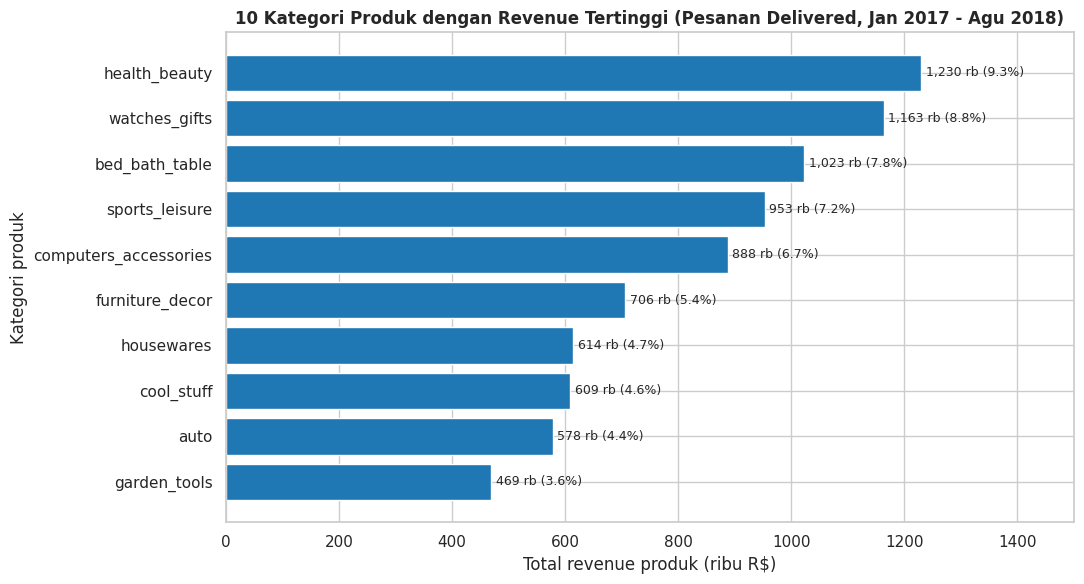

In [21]:
plot1 = top10.reset_index().sort_values('revenue', ascending=True)
fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(plot1['category'], plot1['revenue'] / 1e3, color='#1f77b4')
for bar, share in zip(bars, plot1['kontribusi_%']):
    ax.text(bar.get_width() + 8, bar.get_y() + bar.get_height() / 2, f'{bar.get_width():,.0f} rb ({share:.1f}%)', va='center', fontsize=9)
ax.set_title('10 Kategori Produk dengan Revenue Tertinggi (Pesanan Delivered, Jan 2017 - Agu 2018)', fontsize=12, fontweight='bold')
ax.set_xlabel('Total revenue produk (ribu R$)')
ax.set_ylabel('Kategori produk')
ax.set_xlim(0, plot1['revenue'].max() / 1e3 * 1.22)
plt.tight_layout()
plt.show()

### Insight Business Question 1: Kategori Produk dengan Revenue Tertinggi

Grafik menunjukkan revenue 10 kategori teratas dalam ribu R$ beserta kontribusinya terhadap total revenue. **health_beauty** memimpin dengan 9,3%, disusul **watches_gifts** (8,8%) dan **bed_bath_table** (7,8%). Kategori peringkat 6–10 adalah furniture_decor, housewares, cool_stuff, auto, garden_tools. Sepuluh kategori teratas bersama-sama menyumbang **62,5%** dari total revenue produk, dan 5 teratas 39,9%.

Hal ini menunjukkan revenue **terkonsentrasi pada sejumlah kecil kategori**, tetapi tidak ada satu kategori yang mendominasi (kategori terbesar hanya 9,3%), sehingga pendapatan relatif terdiversifikasi.

Temuan ini menjawab pertanyaan bisnis karena menetapkan kategori yang layak diprioritaskan untuk stok dan promosi, serta besarnya kontribusi 10 kategori teratas.

### Visualisasi Business Question 2: Tren Bulanan Pesanan dan Revenue

**Pertanyaan bisnis:** Bagaimana tren jumlah pesanan dan total revenue produk per bulan dari pesanan berstatus delivered selama Januari 2017 – Agustus 2018, bulan mana yang menjadi puncak, dan berapa persen pertumbuhan Januari–Agustus 2018 dibanding Januari–Agustus 2017, sehingga tim operasional dapat menyiapkan kapasitas dan kampanye pada periode puncak?

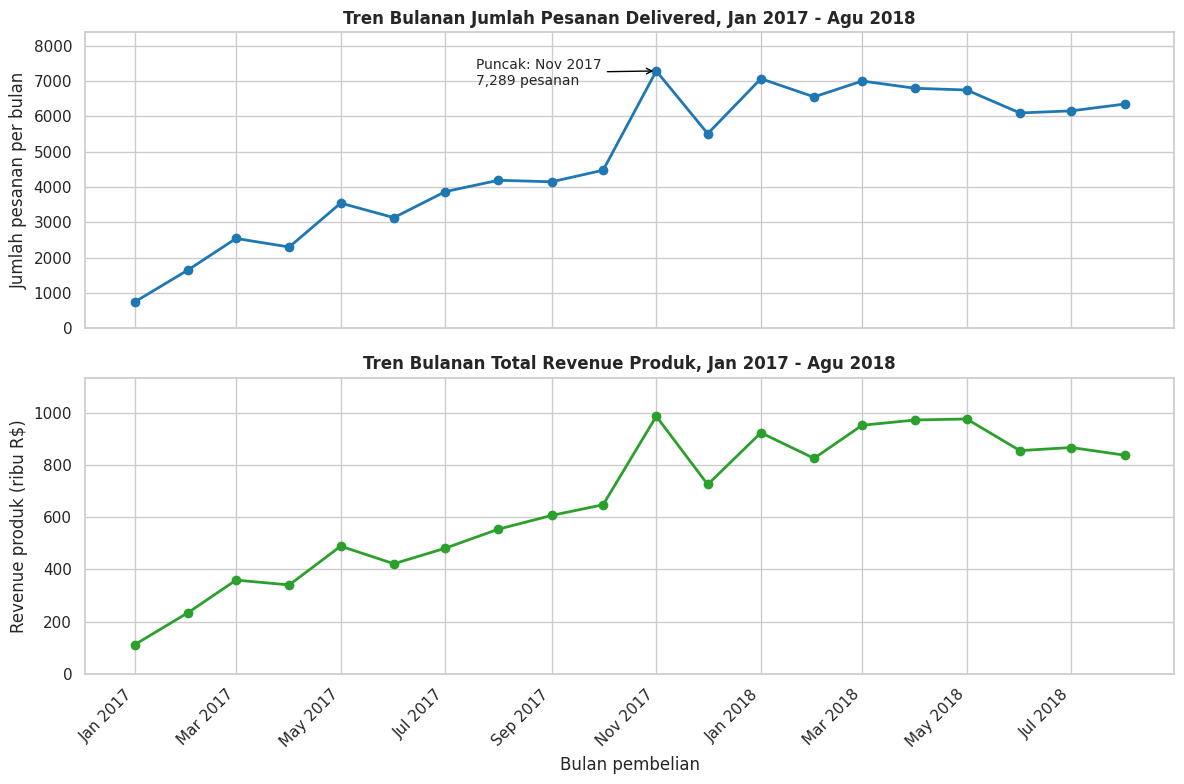

In [22]:
plot2 = monthly.copy()
plot2.index = plot2.index.to_timestamp()
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(plot2.index, plot2['pesanan'], marker='o', color='#1f77b4', linewidth=2)
axes[0].set_title('Tren Bulanan Jumlah Pesanan Delivered, Jan 2017 - Agu 2018', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Jumlah pesanan per bulan')
axes[0].set_ylim(0, plot2['pesanan'].max() * 1.15)
pk = plot2['pesanan'].idxmax()
axes[0].annotate(f"Puncak: {pk:%b %Y}\n{plot2['pesanan'].max():,} pesanan", xy=(pk, plot2['pesanan'].max()),
                 xytext=(-130, -10), textcoords='offset points', arrowprops=dict(arrowstyle='->', color='black'), fontsize=10)

axes[1].plot(plot2.index, plot2['revenue'] / 1e3, marker='o', color='#2ca02c', linewidth=2)
axes[1].set_title('Tren Bulanan Total Revenue Produk, Jan 2017 - Agu 2018', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Revenue produk (ribu R$)')
axes[1].set_xlabel('Bulan pembelian')
axes[1].set_ylim(0, plot2['revenue'].max() / 1e3 * 1.15)
axes[1].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%b %Y'))
axes[1].set_xticks(plot2.index[::2])
plt.setp(axes[1].get_xticklabels(), rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Insight Business Question 2: Tren Bulanan Pesanan dan Revenue

Kedua grafik memperlihatkan tren naik yang jelas sepanjang 2017: pesanan tumbuh dari 750 (Jan 2017) hingga mencapai **puncak 7.289 pesanan pada Nov 2017**, lalu turun pada Desember 2017 dan bertahan stabil di kisaran 6.099–7.069 pesanan per bulan sepanjang 2018. Pola revenue hampir sama dengan pola pesanan, dengan puncak revenue juga pada Nov 2017 (R$ 987.765).

Jan–Agu 2018 tumbuh **+139,9% (pesanan)** dan **+141,1% (revenue)** dibanding Jan–Agu 2017. Karena nilai per pesanan relatif stabil, pertumbuhan terutama berasal dari volume pesanan.

Temuan ini menjawab pertanyaan bisnis karena menunjukkan bulan puncak, besarnya pertumbuhan, dan bahwa lonjakan permintaan bersifat musiman (terpusat pada akhir November), sehingga kapasitas dan kampanye perlu disiapkan sebelum periode tersebut.

### Visualisasi Business Question 3: Keterlambatan Pengiriman dan Skor Ulasan Pelanggan

**Pertanyaan bisnis:** Berapa selisih rata-rata skor ulasan (skala 1–5) antara pesanan yang tiba terlambat dan yang tiba tepat waktu pada pesanan berstatus delivered selama Januari 2017 – Agustus 2018, berapa persen pesanan yang terlambat, dan negara bagian mana yang tingkat keterlambatannya tertinggi, sehingga tim logistik dapat memprioritaskan perbaikan pengiriman?

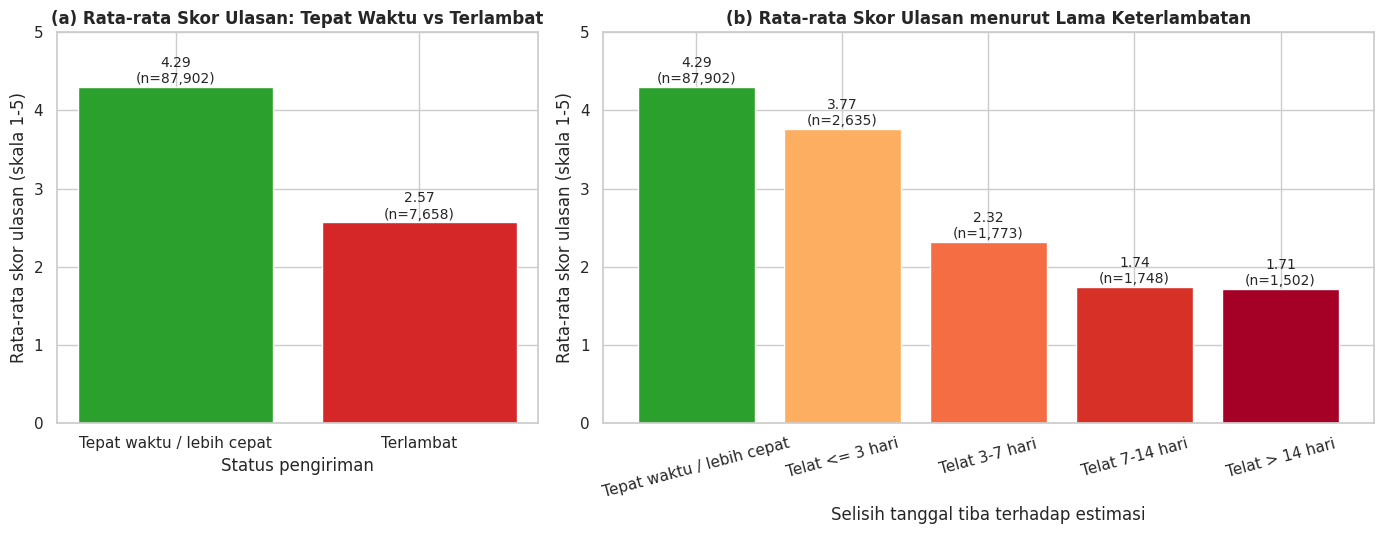

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [1, 1.6]})

order_status_plot = status_summary.reindex(['Tepat waktu / lebih cepat', 'Terlambat']).reset_index()
b1 = axes[0].bar(order_status_plot['status_kirim'], order_status_plot['rata_rata'], color=['#2ca02c', '#d62728'])
for bar, n in zip(b1, order_status_plot['jumlah']):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.05, f'{bar.get_height():.2f}\n(n={n:,})', ha='center', fontsize=10)
axes[0].set_title('(a) Rata-rata Skor Ulasan: Tepat Waktu vs Terlambat', fontweight='bold')
axes[0].set_xlabel('Status pengiriman')
axes[0].set_ylabel('Rata-rata skor ulasan (skala 1-5)')
axes[0].set_ylim(0, 5)

b2 = axes[1].bar(bucket_tbl.index.astype(str), bucket_tbl['rata_rata'], color=['#2ca02c', '#fdae61', '#f46d43', '#d73027', '#a50026'])
for bar, n in zip(b2, bucket_tbl['jumlah']):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.05, f'{bar.get_height():.2f}\n(n={n:,})', ha='center', fontsize=10)
axes[1].set_title('(b) Rata-rata Skor Ulasan menurut Lama Keterlambatan', fontweight='bold')
axes[1].set_xlabel('Selisih tanggal tiba terhadap estimasi')
axes[1].set_ylabel('Rata-rata skor ulasan (skala 1-5)')
axes[1].set_ylim(0, 5)
axes[1].tick_params(axis='x', labelrotation=15)

plt.tight_layout()
plt.show()

### Insight Business Question 3: Keterlambatan Pengiriman dan Skor Ulasan Pelanggan

Grafik (a) menunjukkan pesanan tepat waktu memiliki rata-rata skor **4,29**, sedangkan pesanan terlambat hanya **2,57** (selisih **1,73 poin**). Grafik (b) memperlihatkan skor menurun bertahap seiring lamanya keterlambatan, dari 3,77 (telat <= 3 hari) menjadi sekitar 1,74 dan 1,71 bila telat lebih dari 7 hari. Pesanan terlambat hanya 8,01% dari total, tetapi 54,1% dari mereka memberi skor 1–2.

Temuan ini menjawab pertanyaan bisnis karena mengukur selisih skor (**1,73 poin**), persentase pesanan terlambat (**8,01%**), dan wilayah dengan keterlambatan tertinggi (**MA, CE, BA**) sebagai prioritas perbaikan logistik. Hubungan ini bersifat asosiasi, bukan bukti bahwa keterlambatan satu-satunya penyebab skor rendah.

## Analisis Lanjutan: Segmentasi Pelanggan dengan RFM Analysis

### Tujuan Analisis Lanjutan

**Tujuan:** BQ1–BQ3 menganalisis produk, waktu, dan pengiriman. RFM menambahkan sudut pandang **perilaku pelanggan**: siapa pelanggan bernilai tinggi, siapa yang sudah lama tidak membeli, dan seberapa banyak pelanggan yang membeli ulang. Hasilnya dapat dipakai untuk menentukan target kampanye retensi.

**Definisi (berdasarkan struktur data):**
- **Unit pelanggan:** `customer_unique_id` (bukan `customer_id`, yang berganti pada setiap pesanan).
- **Recency:** jumlah hari dari pembelian terakhir sampai tanggal acuan (sehari setelah pembelian terakhir dalam periode analisis).
- **Frequency:** jumlah pesanan delivered yang unik per pelanggan.
- **Monetary:** total `payment_value` seluruh pesanan delivered pelanggan. Pembayaran sudah diagregasi per pesanan lebih dulu sehingga tidak terhitung ganda akibat join.

**Metode (bukan machine learning):** Recency dan Monetary diberi skor kuintil 1–5 (5 = terbaik). Karena sebagian besar pelanggan hanya memiliki satu pesanan, Frequency dikelompokkan secara manual (1, 2, dan 3+ pesanan). Segmen ditentukan dengan aturan sederhana: pelanggan dengan >= 2 pesanan disebut *Repeat Customers*; pelanggan satu pesanan dibagi menurut recency (skor >= 4 = *Recent*, 3 = *Mid-Recency*, <= 2 = *Lapsed*) dan nilai belanja (skor Monetary >= 4 = *High-Value*).

In [24]:
# Analisis RFM per pelanggan unik (customer_unique_id), hanya pesanan delivered dalam periode analisis
reference_date = order_df['order_purchase_timestamp'].max().normalize() + pd.Timedelta(days=1)
rfm = order_df.groupby('customer_unique_id').agg(
    last_purchase=('order_purchase_timestamp', 'max'),
    frequency=('order_id', 'nunique'),
    monetary=('payment_total', 'sum'))
rfm['recency'] = (reference_date - rfm['last_purchase']).dt.days

# Skor: Recency & Monetary memakai kuintil (rank agar tidak ada batas kembar); Frequency memakai pengelompokan manual
rfm['R_score'] = pd.qcut(rfm['recency'].rank(method='first'), 5, labels=[5, 4, 3, 2, 1]).astype(int)   # 5 = paling baru
rfm['M_score'] = pd.qcut(rfm['monetary'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)  # 5 = belanja terbesar
rfm['F_score'] = np.select([rfm['frequency'] == 1, rfm['frequency'] == 2], [1, 2], default=3)           # 1, 2, 3+ pesanan

def segment(row):
    if row['F_score'] >= 2:
        return 'Repeat Customers'
    if row['R_score'] >= 4:
        return 'Recent High-Value' if row['M_score'] >= 4 else 'Recent Low/Mid-Value'
    if row['R_score'] <= 2:
        return 'Lapsed High-Value' if row['M_score'] >= 4 else 'Lapsed Low/Mid-Value'
    return 'Mid-Recency Customers'

rfm['rfm_segment'] = rfm.apply(segment, axis=1)

print(f'Tanggal acuan recency        : {reference_date.date()}')
print(f'Jumlah pelanggan unik         : {len(rfm):,}')
print('Distribusi frequency (jumlah pesanan):', rfm['frequency'].value_counts().sort_index().head(5).to_dict(), '...')
print(f"Pelanggan dengan 1 pesanan    : {(rfm['frequency'] == 1).mean():.1%}")
display(rfm[['recency', 'frequency', 'monetary']].describe().round(1))

Tanggal acuan recency        : 2018-08-30
Jumlah pelanggan unik         : 93,104
Distribusi frequency (jumlah pesanan): {1: 90315, 2: 2562, 3: 180, 4: 28, 5: 9} ...
Pelanggan dengan 1 pesanan    : 97.0%


,recency,frequency,monetary
count,"93,104.00","93,104.00","93,104.00"
mean,236.20,1.00,165.10
std,150.90,0.20,226.40
min,0.00,1.00,9.60
25%,114.00,1.00,63.00
50%,218.00,1.00,107.80
75%,345.00,1.00,182.50
max,601.00,15.00,"13,664.10"


**Insight:**
- Tanggal acuan 2018-08-30; terdapat 93.104 pelanggan unik. **97,0% pelanggan hanya membeli satu kali**; hanya 2.789 pelanggan yang membeli ulang (maksimum 15 pesanan). Karena itu Frequency memakai pengelompokan manual, bukan kuintil.
- Median recency 218 hari; median total pembayaran R$ 107,8 dan rata-rata R$ 165,1 (rata-rata lebih tinggi daripada median karena segelintir pelanggan berbelanja sangat besar, hingga R$ 13.664).

In [25]:
seg_order = ['Repeat Customers', 'Recent High-Value', 'Recent Low/Mid-Value', 'Mid-Recency Customers', 'Lapsed High-Value', 'Lapsed Low/Mid-Value']
rfm_seg = rfm.groupby('rfm_segment').agg(pelanggan=('monetary', 'size'), rata2_recency_hari=('recency', 'mean'),
                                          rata2_frequency=('frequency', 'mean'), rata2_monetary=('monetary', 'mean'),
                                          total_monetary=('monetary', 'sum')).reindex(seg_order)
rfm_seg['pelanggan_%'] = rfm_seg['pelanggan'] / rfm_seg['pelanggan'].sum() * 100
rfm_seg['kontribusi_monetary_%'] = rfm_seg['total_monetary'] / rfm_seg['total_monetary'].sum() * 100
display(rfm_seg.round(2))

,pelanggan,rata2_recency_hari,rata2_frequency,rata2_monetary,total_monetary,pelanggan_%,kontribusi_monetary_%
rfm_segment,,,,,,,
Repeat Customers,2789,219.11,2.11,308.62,"860,754.56",3.00,5.60
Recent High-Value,14373,90.64,1.00,302.09,"4,341,951.17",15.44,28.24
Recent Low/Mid-Value,21672,89.11,1.00,72.90,"1,579,977.28",23.28,10.28
Mid-Recency Customers,18019,218.84,1.00,151.70,"2,733,565.35",19.35,17.78
Lapsed High-Value,13737,390.51,1.00,307.39,"4,222,638.45",14.75,27.46
Lapsed Low/Mid-Value,22514,392.73,1.00,72.71,"1,636,988.63",24.18,10.65


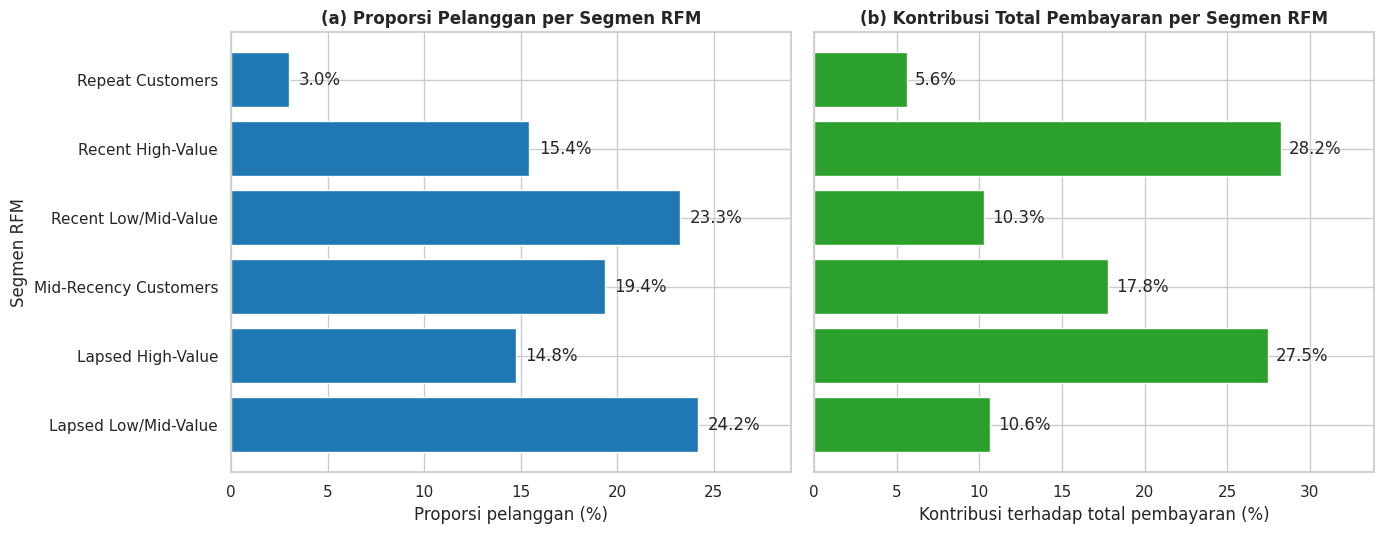

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
seg_plot = rfm_seg.reset_index()
axes[0].barh(seg_plot['rfm_segment'], seg_plot['pelanggan_%'], color='#1f77b4')
for i, v in enumerate(seg_plot['pelanggan_%']):
    axes[0].text(v + 0.5, i, f'{v:.1f}%', va='center')
axes[0].set_title('(a) Proporsi Pelanggan per Segmen RFM', fontweight='bold')
axes[0].set_xlabel('Proporsi pelanggan (%)')
axes[0].set_ylabel('Segmen RFM')
axes[0].set_xlim(0, seg_plot['pelanggan_%'].max() * 1.2)
axes[0].invert_yaxis()

axes[1].barh(seg_plot['rfm_segment'], seg_plot['kontribusi_monetary_%'], color='#2ca02c')
for i, v in enumerate(seg_plot['kontribusi_monetary_%']):
    axes[1].text(v + 0.5, i, f'{v:.1f}%', va='center')
axes[1].set_title('(b) Kontribusi Total Pembayaran per Segmen RFM', fontweight='bold')
axes[1].set_xlabel('Kontribusi terhadap total pembayaran (%)')
axes[1].set_xlim(0, seg_plot['kontribusi_monetary_%'].max() * 1.2)
plt.tight_layout()
plt.show()

**Insight:**
- **Repeat Customers**: 2.789 pelanggan (3,0%), rata-rata recency 219 hari, rata-rata pembayaran R$ 308,6, kontribusi pembayaran 5,6%.
- **Recent High-Value**: 14.373 pelanggan (15,4%), rata-rata recency 91 hari, rata-rata pembayaran R$ 302,1, kontribusi pembayaran 28,2%.
- **Recent Low/Mid-Value**: 21.672 pelanggan (23,3%), rata-rata recency 89 hari, rata-rata pembayaran R$ 72,9, kontribusi pembayaran 10,3%.
- **Mid-Recency Customers**: 18.019 pelanggan (19,4%), rata-rata recency 219 hari, rata-rata pembayaran R$ 151,7, kontribusi pembayaran 17,8%.
- **Lapsed High-Value**: 13.737 pelanggan (14,8%), rata-rata recency 391 hari, rata-rata pembayaran R$ 307,4, kontribusi pembayaran 27,5%.
- **Lapsed Low/Mid-Value**: 22.514 pelanggan (24,2%), rata-rata recency 393 hari, rata-rata pembayaran R$ 72,7, kontribusi pembayaran 10,6%.
- Pelanggan *High-Value* (belanja kuintil 4–5, satu pesanan) hanya 30,2% dari seluruh pelanggan, tetapi menyumbang **55,7% total pembayaran**. Sebagai pembanding, 20% pelanggan dengan pembayaran terbesar menyumbang 53,5% total pembayaran.
- Segmen *Lapsed High-Value* (13.737 pelanggan) dan *Recent High-Value* (14.373 pelanggan) adalah target prioritas kampanye: yang pertama untuk reaktivasi, yang kedua untuk mendorong pembelian kedua selagi pelanggan masih baru.
- Segmentasi ini berbasis perilaku pembelian historis pada periode analisis, bukan prediksi.

### Menyimpan data bersih untuk dashboard

**Tujuan:** dashboard Streamlit memakai data yang sama persis dengan notebook sehingga angka dan kategori konsisten. **Struktur:** 1 baris per item pesanan; jumlah pesanan dan pelanggan dihitung dari kode unik (`order_code`, `customer_code`) agar tidak terhitung ganda. ID asli diganti kode numerik agar file lebih ringan.

In [27]:
os.makedirs('dashboard', exist_ok=True)

main_data = (items_delivered[['order_id', 'order_item_id', 'category', 'price', 'freight_value']]
             .merge(order_df[['order_id', 'customer_unique_id', 'customer_state', 'order_purchase_timestamp',
                              'review_score', 'days_late', 'is_late', 'delay_bucket']], on='order_id', how='left')
             .merge(rfm[['rfm_segment']], left_on='customer_unique_id', right_index=True, how='left'))

# ID asli diganti kode numerik agar file ringan (dipakai dashboard hanya untuk menghitung jumlah pesanan/pelanggan unik)
main_data['order_code'] = pd.factorize(main_data['order_id'])[0]
main_data['customer_code'] = pd.factorize(main_data['customer_unique_id'])[0]
main_data['purchase_date'] = main_data['order_purchase_timestamp'].dt.strftime('%Y-%m-%d')
main_data['days_late'] = main_data['days_late'].round(2)
main_data['delay_bucket'] = main_data['delay_bucket'].astype(str).replace('nan', np.nan)

main_data = main_data[['order_code', 'customer_code', 'purchase_date', 'customer_state', 'category', 'price', 'freight_value',
                       'review_score', 'days_late', 'is_late', 'delay_bucket', 'rfm_segment']]
main_data.to_csv('dashboard/main_data.csv', index=False)

print(f'main_data.csv tersimpan: {len(main_data):,} baris (1 baris per item) x {main_data.shape[1]} kolom')
print(f"Pesanan unik: {main_data['order_code'].nunique():,} | pelanggan unik: {main_data['customer_code'].nunique():,}")
print(f"Total revenue: R$ {main_data['price'].sum():,.2f}")
print('Cek konsistensi dengan order_df:', main_data['order_code'].nunique() == len(order_df), np.isclose(main_data['price'].sum(), order_df['price_total'].sum()))

main_data.csv tersimpan: 109,880 baris (1 baris per item) x 12 kolom
Pesanan unik: 96,211 | pelanggan unik: 93,104
Total revenue: R$ 13,181,027.13
Cek konsistensi dengan order_df: True True


## Conclusion & Recommendation

### Conclusion

1. **Business Question 1 (Kategori Produk dengan Revenue Tertinggi):** Kategori produk apa saja yang menghasilkan total revenue produk (jumlah harga item, tidak termasuk ongkos kirim) tertinggi dari pesanan berstatus delivered selama 1 Januari 2017 – 31 Agustus 2018, dan berapa persen kontribusi 10 kategori teratas terhadap total revenue, sehingga tim merchandising dapat memprioritaskan stok dan promosi pada kategori tersebut?

   **Jawaban:** Kategori dengan revenue tertinggi adalah **health_beauty** (R$ 1.229.558; 9,3%), **watches_gifts** (R$ 1.163.466; 8,8%), dan **bed_bath_table** (R$ 1.022.956; 7,8%), diikuti sports_leisure dan computers_accessories. **Sepuluh kategori teratas menyumbang 62,5%** dari total revenue produk R$ 13.181.027 (5 teratas 39,9%). Revenue terkonsentrasi pada sebagian kategori, tetapi tidak didominasi satu kategori. Peringkat revenue berbeda dari volume: `bed_bath_table` terjual paling banyak (10.945 item) tetapi berharga rendah (rata-rata R$ 93,5).

2. **Business Question 2 (Tren Bulanan Pesanan dan Revenue):** Bagaimana tren jumlah pesanan dan total revenue produk per bulan dari pesanan berstatus delivered selama Januari 2017 – Agustus 2018, bulan mana yang menjadi puncak, dan berapa persen pertumbuhan Januari–Agustus 2018 dibanding Januari–Agustus 2017, sehingga tim operasional dapat menyiapkan kapasitas dan kampanye pada periode puncak?

   **Jawaban:** Pesanan bulanan tumbuh dari 750 (Jan 2017) dan mencapai **puncak 7.289 pesanan pada Nov 2017** (revenue R$ 987.765), terpusat pada 2017-11-24 dengan 1.147 pesanan dalam sehari. Sepanjang 2018 permintaan stabil di 6.099–7.069 pesanan per bulan. **Jan–Agu 2018 tumbuh +139,9% (pesanan) dan +141,1% (revenue)** dibanding Jan–Agu 2017, terutama karena jumlah pesanan, bukan nilai per pesanan.

3. **Business Question 3 (Keterlambatan Pengiriman dan Skor Ulasan Pelanggan):** Berapa selisih rata-rata skor ulasan (skala 1–5) antara pesanan yang tiba terlambat dan yang tiba tepat waktu pada pesanan berstatus delivered selama Januari 2017 – Agustus 2018, berapa persen pesanan yang terlambat, dan negara bagian mana yang tingkat keterlambatannya tertinggi, sehingga tim logistik dapat memprioritaskan perbaikan pengiriman?

   **Jawaban:** Sebanyak **8,01%** pesanan tiba terlambat. Rata-rata skor ulasan pesanan tepat waktu **4,29** vs **2,57** untuk pesanan terlambat (**selisih 1,73 poin**); skor 1–2 mencapai 54,1% pada pesanan terlambat vs 9,2% pada pesanan tepat waktu. Keterlambatan paling tinggi di **MA (19,3%)**, **CE (15,3%)**, dan **BA (13,7%)**, dibanding SP 5,8%. Hubungan ini adalah asosiasi, bukan bukti sebab-akibat.

4. **Analisis lanjutan (RFM):** 97,0% pelanggan hanya membeli sekali. Pelanggan *High-Value* satu pesanan (30,2% pelanggan) menyumbang 55,7% total pembayaran, dan terbagi pada segmen *Recent High-Value* (14.373 pelanggan) serta *Lapsed High-Value* (13.737 pelanggan).

**Rekomendasi Action Item** (diturunkan langsung dari temuan di atas):

1. **Prioritaskan stok dan promosi pada kategori inti (dari BQ1).** Pastikan ketersediaan stok untuk 5 kategori teratas (health_beauty, watches_gifts, bed_bath_table, sports_leisure, computers_accessories) yang menyumbang 39,9% revenue. Untuk `bed_bath_table` (volume tertinggi, harga rata-rata rendah) manfaatkan paket bundling atau upsell untuk menaikkan nilai per pesanan; untuk `watches_gifts` (harga rata-rata tinggi) fokuskan promosi pada nilai produk.
2. **Siapkan kapasitas dan kampanye menjelang akhir November (dari BQ2).** Lonjakan 62,8% pada Nov 2017 dan 1.147 pesanan pada 2017-11-24 menunjukkan permintaan sangat terkonsentrasi; stok, tim, dan kapasitas pengiriman perlu disiapkan sebelum periode ini, lalu dievaluasi kembali karena pesanan turun -24,4% pada bulan berikutnya.
3. **Perbaiki pengiriman di wilayah dengan keterlambatan tertinggi (dari BQ3).** Prioritaskan MA (19,3%), CE (15,3%), BA (13,7%) dengan menambah kapasitas kurir atau mengevaluasi estimasi pengiriman, serta menghindari keterlambatan lebih dari 7 hari karena skor jatuh ke sekitar 1,74–1,71. Pantau tingkat keterlambatan per negara bagian sebagai KPI bulanan.
4. **Kampanye retensi berbasis RFM (dari analisis lanjutan).** Reaktivasi segmen *Lapsed High-Value* (13.737 pelanggan; 27,5% total pembayaran) dengan voucher atau penawaran khusus, dan dorong pembelian kedua pada *Recent High-Value* (14.373 pelanggan) karena hanya 3,0% pelanggan yang membeli ulang.

**Catatan keterbatasan:** (a) analisis memakai pesanan `delivered` pada 1 Jan 2017 – 31 Agu 2018; (b) 349 pesanan di luar periode dan pesanan non-delivered tidak dianalisis; (c) hubungan keterlambatan dan skor ulasan bersifat asosiasi; (d) kaitan lonjakan 24 November 2017 dengan Black Friday adalah dugaan karena data promosi tidak tersedia; (e) segmentasi RFM didominasi pelanggan satu pesanan sehingga Frequency tidak membedakan sebagian besar pelanggan.